# Classification d'articles AG News : TF-IDF contre DistilBERT

**Auteur :** DOWOU Issa · Licence IT, IA & Big Data

---

### 1. Présentation de la problématique

  **Contexte.** La classification automatique de textes courts (titres et descriptions d'articles de presse) est une tâche centrale en NLP : elle alimente les moteurs de recommandation d'actualités, le filtrage de contenu, la veille concurrentielle, etc.

  **Dataset réel.** [AG News](https://huggingface.co/datasets/ag_news) — 120 000 articles d'entraînement et 7 600 articles de test, répartis en **4 classes** :
  1. **World** (international)
  2. **Sports**
  3. **Business**
  4. **Sci/Tech**

  Chaque exemple contient un *Title* et une *Description* courte (1 à 3 phrases).

  **Contexte technique.**
  Ce projet illustre concrètement la rupture apportée par les **Transformers** (Vaswani et al., 2017) :
  - mécanisme d'**attention** au lieu de la récurrence,
  - entraînement parallélisable,
  - utilisation du **transfer learning** via des modèles pré-entraînés à grande échelle (BERT, DistilBERT, etc.) que l'on **fine-tune** sur une tâche cible.

  On comparera une **baseline classique** (TF-IDF + régression logistique) à un **Transformer pré-entraîné fine-tuné** (DistilBERT) afin de mesurer concrètement le gain apporté par cette architecture.

### 2. Installation des dépendances

> Exécute cette cellule **une seule fois** au démarrage (Google Colab recommandé, GPU activé : *Runtime → Change runtime type → GPU*).

In [1]:
!pip install -q -U transformers datasets evaluate accelerate huggingface_hub scikit-learn matplotlib seaborn pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 4.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 76.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 24.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 42.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 60.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 77.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 70.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
dask-cudf-cu13 26.6.0

In [2]:
import os, math, random, time, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch.utils.data import DataLoader
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", DEVICE)
print("Torch  :", torch.__version__)


Device : cuda
Torch  : 2.11.0+cu130


### 3. Chargement du dataset AG News

Deux options :
- **(A)** Charger le CSV local fourni (`train.csv`, `test.csv`) — colonnes : *Class Index, Title, Description*.
- **(B)** Charger directement depuis HuggingFace Datasets (recommandé en Colab).

On utilise (B) par défaut ; la fonction `load_local_csv` est fournie en alternative.

In [3]:
from datasets import load_dataset, Dataset, DatasetDict

USE_LOCAL_CSV = False  # passe à True si tu veux charger depuis tes fichiers CSV

LABELS = ["World", "Sports", "Business", "Sci/Tech"]
ID2LABEL = {i: l for i, l in enumerate(LABELS)}
LABEL2ID = {l: i for i, l in enumerate(LABELS)}

def load_local_csv(train_path, test_path):
    df_tr = pd.read_csv(train_path, header=None,
                        names=["label", "title", "description"]) if pd.read_csv(train_path, nrows=1).columns[0].strip().lower().startswith("class") is False               else pd.read_csv(train_path).rename(columns={"Class Index":"label","Title":"title","Description":"description"})
    df_te = pd.read_csv(test_path).rename(columns={"Class Index":"label","Title":"title","Description":"description"})               if "Class Index" in pd.read_csv(test_path, nrows=1).columns               else pd.read_csv(test_path, header=None, names=["label","title","description"])
    # AG News labels are 1..4 -> remap to 0..3
    df_tr["label"] = df_tr["label"].astype(int) - 1
    df_te["label"] = df_te["label"].astype(int) - 1
    df_tr["text"] = df_tr["title"].fillna("") + ". " + df_tr["description"].fillna("")
    df_te["text"] = df_te["title"].fillna("") + ". " + df_te["description"].fillna("")
    return DatasetDict({
        "train": Dataset.from_pandas(df_tr[["text","label"]], preserve_index=False),
        "test":  Dataset.from_pandas(df_te[["text","label"]], preserve_index=False),
    })

if USE_LOCAL_CSV:
    ds = load_local_csv("train.csv", "test.csv")
else:
    raw = load_dataset("fancyzhx/ag_news")
    # uniformise sous forme {"text","label"}
    ds = DatasetDict({
        split: raw[split].map(lambda ex: {"text": ex["text"], "label": ex["label"]},
                              remove_columns=[c for c in raw[split].column_names if c not in ("text","label")])
        for split in raw.keys()
    })

print(ds)

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Map:   0%|          | 0/120000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


### 4. Exploration et analyse des données (EDA)

In [4]:
df_train = ds["train"].to_pandas()
df_test  = ds["test"].to_pandas()
print(f"Train : {len(df_train):,} exemples — Test : {len(df_test):,} exemples")
df_train.head(3)

Train : 120,000 exemples — Test : 7,600 exemples


,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2


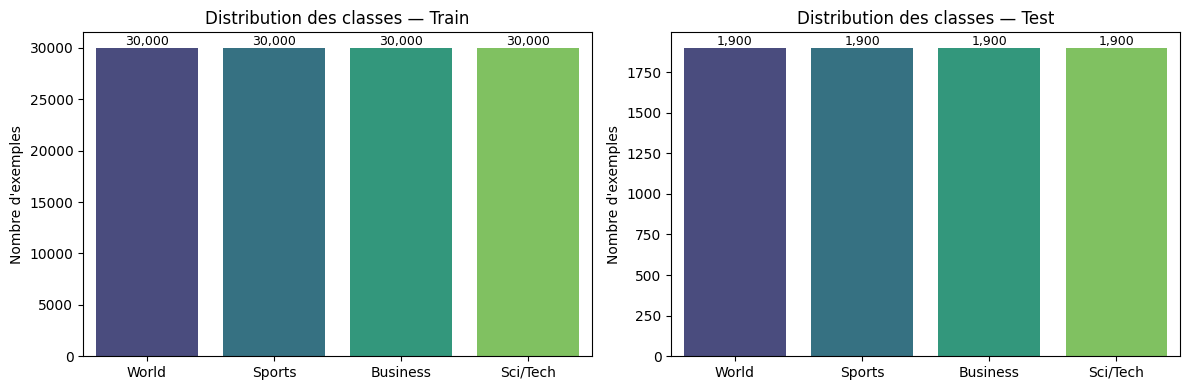

In [5]:
# Distribution des classes
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, df, name in zip(axes, [df_train, df_test], ["Train", "Test"]):
    counts = df["label"].map(ID2LABEL).value_counts().reindex(LABELS)
    sns.barplot(x=counts.index, y=counts.values, ax=ax, palette="viridis")
    ax.set_title(f"Distribution des classes — {name}")
    ax.set_ylabel("Nombre d'exemples"); ax.set_xlabel("")
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

count    120000.0
mean         37.8
std          10.1
min           8.0
25%          32.0
50%          37.0
75%          43.0
max         177.0
Name: n_words, dtype: float64


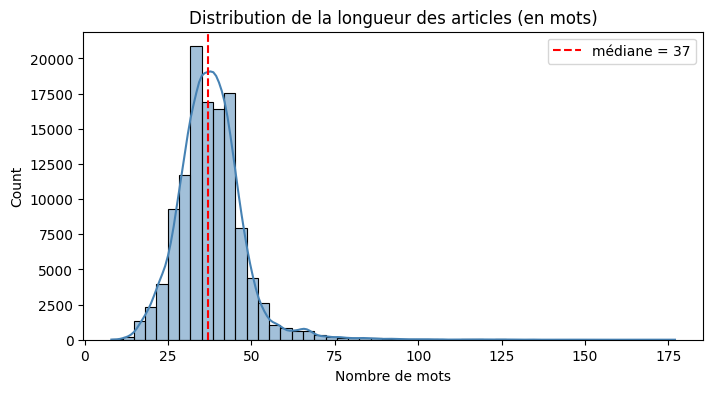

In [6]:
# Longueur des textes (en mots)
df_train["n_words"] = df_train["text"].str.split().str.len()
print(df_train["n_words"].describe().round(1))

plt.figure(figsize=(8,4))
sns.histplot(df_train["n_words"], bins=50, kde=True, color="steelblue")
plt.axvline(df_train["n_words"].median(), color="red", linestyle="--", label=f"médiane = {df_train['n_words'].median():.0f}")
plt.title("Distribution de la longueur des articles (en mots)")
plt.xlabel("Nombre de mots"); plt.legend(); plt.show()

In [7]:
# Quelques exemples par classe
for c in range(4):
    print(f"\n=== Classe {c} — {ID2LABEL[c]} ===")
    for txt in df_train[df_train.label==c]["text"].head(2).tolist():
        print(" •", txt[:180], "...")


=== Classe 0 — World ===
 • Venezuelans Vote Early in Referendum on Chavez Rule (Reuters) Reuters - Venezuelans turned out early\and in large numbers on Sunday to vote in a historic referendum\that will eithe ...
 • S.Koreans Clash with Police on Iraq Troop Dispatch (Reuters) Reuters - South Korean police used water cannon in\central Seoul Sunday to disperse at least 7,000 protesters\urging th ...

=== Classe 1 — Sports ===
 • Phelps, Thorpe Advance in 200 Freestyle (AP) AP - Michael Phelps took care of qualifying for the Olympic 200-meter freestyle semifinals Sunday, and then found out he had been added ...
 • Reds Knock Padres Out of Wild-Card Lead (AP) AP - Wily Mo Pena homered twice and drove in four runs, helping the Cincinnati Reds beat the San Diego Padres 11-5 on Saturday night. S ...

=== Classe 2 — Business ===
 • Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again. ...
 • Carlyle Loo

**Observations EDA :**
- Le dataset est **parfaitement équilibré** (30 000 exemples par classe en train, 1 900 en test) → l'accuracy est une métrique fiable.
- Les textes sont **courts** (médiane ≈ 35 mots) → un *max_length* de 128 tokens est largement suffisant pour BERT.
- Pas de valeurs manquantes notables après concaténation `title + description`.

### 5. Prétraitement

#### 5.1. Pour la baseline (ML classique)
- Vectorisation **TF-IDF** (uni + bigrammes), suppression des stop-words anglais, vocabulaire limité à 50 000 termes.

#### 5.2. Pour le Transformer
- **Tokenization** avec le tokenizer de DistilBERT (sub-words / WordPiece).
- Padding/troncature à `max_length=128`.

In [8]:
# ---- Sous-échantillonnage optionnel pour aller plus vite en démo ----
SUBSAMPLE_TRAIN = 20000   # mets None pour utiliser tout le train (120k)
SUBSAMPLE_TEST  = None

def subsample(d, n, seed=SEED):
    if n is None or n >= len(d): return d
    return d.shuffle(seed=seed).select(range(n))

ds_small = DatasetDict({
    "train": subsample(ds["train"], SUBSAMPLE_TRAIN),
    "test":  subsample(ds["test"],  SUBSAMPLE_TEST),
})
print(ds_small)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 20000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


### 6. Baseline — TF-IDF + Régression Logistique

In [9]:
X_train_txt = ds_small["train"]["text"]
y_train     = np.array(ds_small["train"]["label"])
X_test_txt  = ds_small["test"]["text"]
y_test      = np.array(ds_small["test"]["label"])

t0 = time.time()
vectorizer = TfidfVectorizer(
    ngram_range=(1,2), max_features=50000, min_df=2, stop_words="english", sublinear_tf=True)
Xtr = vectorizer.fit_transform(X_train_txt)
Xte = vectorizer.transform(X_test_txt)
print(f"TF-IDF : {Xtr.shape[1]:,} features — fit en {time.time()-t0:.1f}s")

t0 = time.time()
clf = LogisticRegression(max_iter=1000, n_jobs=-1, C=1.0)
clf.fit(Xtr, y_train)
print(f"Régression logistique entraînée en {time.time()-t0:.1f}s")

y_pred_base = clf.predict(Xte)
acc_base = accuracy_score(y_test, y_pred_base)
prec_b, rec_b, f1_b, _ = precision_recall_fscore_support(y_test, y_pred_base, average="macro")
print(f"\n[BASELINE]  accuracy = {acc_base:.4f}  |  macro-P={prec_b:.4f}  R={rec_b:.4f}  F1={f1_b:.4f}")
print("\n", classification_report(y_test, y_pred_base, target_names=LABELS, digits=4))

TF-IDF : 50,000 features — fit en 9.4s
Régression logistique entraînée en 8.6s

[BASELINE]  accuracy = 0.9058  |  macro-P=0.9053  R=0.9058  F1=0.9054

               precision    recall  f1-score   support

       World     0.9169    0.9000    0.9084      1900
      Sports     0.9428    0.9795    0.9608      1900
    Business     0.8755    0.8626    0.8690      1900
    Sci/Tech     0.8862    0.8811    0.8836      1900

    accuracy                         0.9058      7600
   macro avg     0.9053    0.9058    0.9054      7600
weighted avg     0.9053    0.9058    0.9054      7600



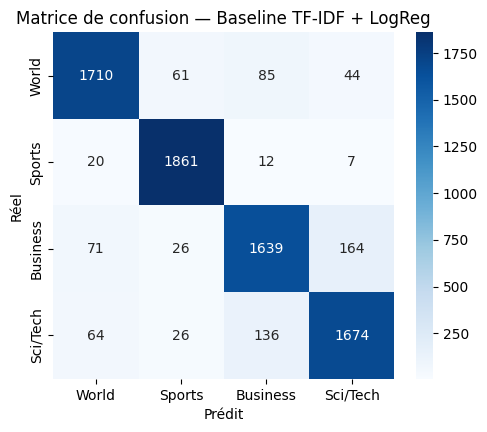

In [10]:
cm = confusion_matrix(y_test, y_pred_base)
plt.figure(figsize=(5.5,4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS)
plt.title("Matrice de confusion — Baseline TF-IDF + LogReg")
plt.xlabel("Prédit"); plt.ylabel("Réel"); plt.show()

### 7. Modèle Deep Learning — Fine-tuning d'un Transformer (DistilBERT)

**Pourquoi DistilBERT ?** C'est une version distillée de BERT, ~40 % plus petite et ~60 % plus rapide tout en conservant ~97 % des performances. Idéal pour un projet pédagogique où l'on veut un bon ratio performance/temps.

> Le concept clé du cours : on **réutilise les poids pré-entraînés** sur Wikipedia + BookCorpus (transfer learning) et on n'apprend que la tête de classification + un léger ajustement des couches.

In [11]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)
import evaluate

MODEL_NAME = "distilbert-base-uncased"
MAX_LEN = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_fn(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)

ds_tok = ds_small.map(tokenize_fn, batched=True, remove_columns=["text"])
ds_tok = ds_tok.rename_column("label", "labels")
ds_tok.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])
print(ds_tok)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 20000
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 7600
    })
})


In [12]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=4, id2label=ID2LABEL, label2id=LABEL2ID)

n_params = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Paramètres totaux : {n_params:,}")
print(f"Paramètres entraînables : {n_trainable:,}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Paramètres totaux : 66,956,548
Paramètres entraînables : 66,956,548


In [13]:
accuracy_metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="macro")
    acc = accuracy_score(labels, preds)
    return {"accuracy": acc, "precision_macro": p, "recall_macro": r, "f1_macro": f1}

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Compatible avec transformers 4.x et 5.x : warmup calculé en nombre de pas,
# et arguments filtrés selon la version installée.
import inspect
EPOCHS, BATCH = 2, 32
steps_total = math.ceil(len(ds_tok["train"]) / BATCH) * EPOCHS
args_kwargs = dict(
    output_dir="./distilbert-agnews",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=int(0.1 * steps_total),
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    report_to="none",
    fp16=torch.cuda.is_available(),
    seed=SEED,
)
ta_params = inspect.signature(TrainingArguments.__init__).parameters
if "eval_strategy" not in ta_params:            # anciennes versions
    args_kwargs["evaluation_strategy"] = args_kwargs.pop("eval_strategy")
training_args = TrainingArguments(**{k: v for k, v in args_kwargs.items() if k in ta_params or k == "evaluation_strategy"})

trainer_kwargs = dict(
    model=model,
    args=training_args,
    train_dataset=ds_tok["train"],
    eval_dataset=ds_tok["test"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)
# transformers >= 4.46 : "processing_class" remplace "tokenizer"
if "processing_class" in inspect.signature(Trainer.__init__).parameters:
    trainer_kwargs["processing_class"] = tokenizer
else:
    trainer_kwargs["tokenizer"] = tokenizer
trainer = Trainer(**trainer_kwargs)

t0 = time.time()
train_result = trainer.train()
train_time = time.time() - t0
print(f"\nFine-tuning terminé en {train_time/60:.1f} min")

Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,0.258710,0.251058,0.915921,0.916527,0.915921,0.915954
2,0.183235,0.235515,0.923158,0.923252,0.923158,0.923095


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Fine-tuning terminé en 2.7 min


In [14]:
# Évaluation finale
eval_metrics = trainer.evaluate()
print("\n[TRANSFORMER]  ", {k: round(v,4) for k,v in eval_metrics.items() if isinstance(v,float)})

# Prédictions pour analyses détaillées
pred_out = trainer.predict(ds_tok["test"])
y_pred_tr = np.argmax(pred_out.predictions, axis=-1)
y_true    = pred_out.label_ids

print("\n", classification_report(y_true, y_pred_tr, target_names=LABELS, digits=4))

Training Loss,Validation Loss,Epoch,Accuracy,Precision Macro,Recall Macro,F1 Macro
0.183235,0.235515,2,0.923158,0.923252,0.923158,0.923095



[TRANSFORMER]   {'eval_loss': 0.2355, 'eval_accuracy': 0.9232, 'eval_precision_macro': 0.9233, 'eval_recall_macro': 0.9232, 'eval_f1_macro': 0.9231}



               precision    recall  f1-score   support

       World     0.9373    0.9279    0.9326      1900
      Sports     0.9754    0.9805    0.9780      1900
    Business     0.8960    0.8711    0.8834      1900
    Sci/Tech     0.8843    0.9132    0.8985      1900

    accuracy                         0.9232      7600
   macro avg     0.9233    0.9232    0.9231      7600
weighted avg     0.9233    0.9232    0.9231      7600



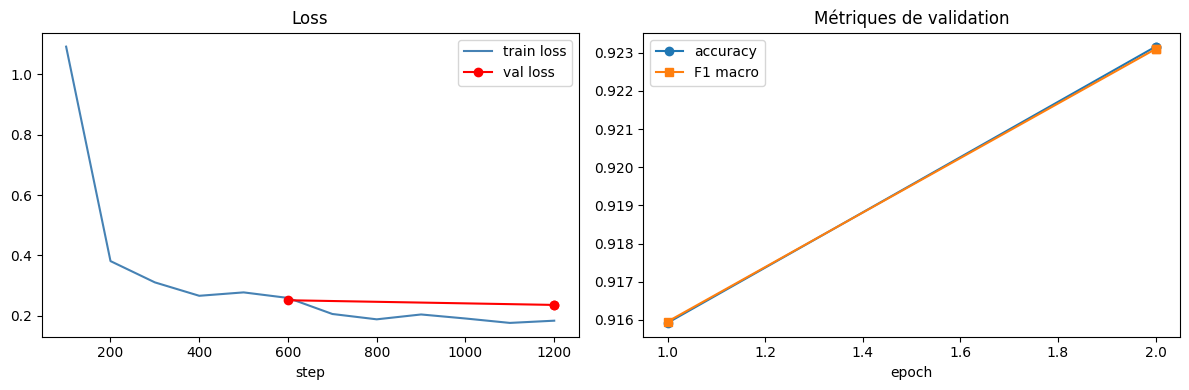

In [15]:
# Courbes d'apprentissage
log_hist = pd.DataFrame(trainer.state.log_history)
train_loss = log_hist.dropna(subset=["loss"])[["step","loss"]]
eval_rows  = log_hist.dropna(subset=["eval_loss"])[["epoch","eval_loss","eval_accuracy","eval_f1_macro"]]

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(train_loss["step"], train_loss["loss"], label="train loss", color="steelblue")
if not eval_rows.empty:
    # convertit epoch -> step approximatif pour l'affichage
    steps_per_epoch = train_loss["step"].max() / eval_rows["epoch"].max()
    axes[0].plot(eval_rows["epoch"]*steps_per_epoch, eval_rows["eval_loss"],
                 "o-", color="red", label="val loss")
axes[0].set_title("Loss"); axes[0].set_xlabel("step"); axes[0].legend()

if not eval_rows.empty:
    axes[1].plot(eval_rows["epoch"], eval_rows["eval_accuracy"], "o-", label="accuracy")
    axes[1].plot(eval_rows["epoch"], eval_rows["eval_f1_macro"], "s-", label="F1 macro")
    axes[1].set_title("Métriques de validation"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

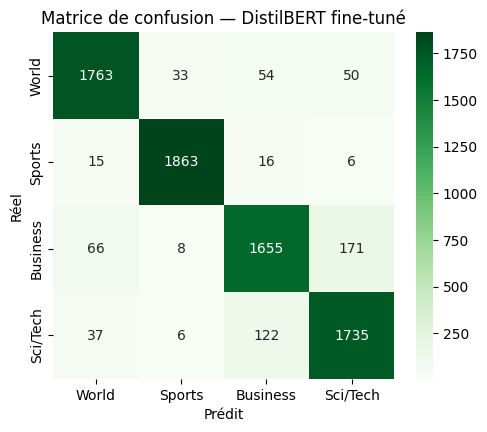

In [16]:
cm_tr = confusion_matrix(y_true, y_pred_tr)
plt.figure(figsize=(5.5,4.5))
sns.heatmap(cm_tr, annot=True, fmt="d", cmap="Greens", xticklabels=LABELS, yticklabels=LABELS)
plt.title("Matrice de confusion — DistilBERT fine-tuné")
plt.xlabel("Prédit"); plt.ylabel("Réel"); plt.show()

### 8. Comparaison rigoureuse des deux approches

In [17]:
acc_tr = accuracy_score(y_true, y_pred_tr)
p_tr, r_tr, f1_tr, _ = precision_recall_fscore_support(y_true, y_pred_tr, average="macro")

results = pd.DataFrame({
    "Modèle":           ["TF-IDF + LogReg (baseline)", "DistilBERT fine-tuné"],
    "Accuracy":         [acc_base, acc_tr],
    "Precision (macro)":[prec_b,   p_tr],
    "Recall (macro)":   [rec_b,    r_tr],
    "F1 (macro)":       [f1_b,     f1_tr],
    "Paramètres":       ["~50 000 (vocab TF-IDF)", f"{n_params/1e6:.1f} M"],
}).round(4)
results

,Modèle,Accuracy,Precision (macro),Recall (macro),F1 (macro),Paramètres
0,TF-IDF + LogReg (baseline),0.9058,0.9053,0.9058,0.9054,~50 000 (vocab TF-IDF)
1,DistilBERT fine-tuné,0.9232,0.9233,0.9232,0.9231,67.0 M


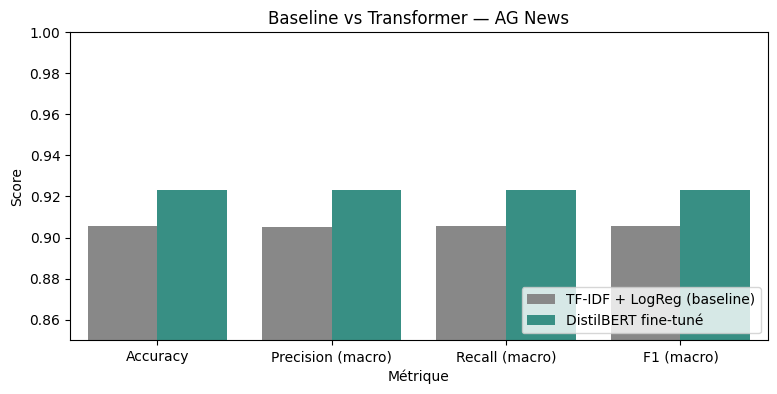

In [18]:
# Visualisation comparative
metrics_df = results.melt(id_vars=["Modèle"],
                          value_vars=["Accuracy","Precision (macro)","Recall (macro)","F1 (macro)"],
                          var_name="Métrique", value_name="Score")
plt.figure(figsize=(9,4))
sns.barplot(data=metrics_df, x="Métrique", y="Score", hue="Modèle", palette=["#888","#2a9d8f"])
plt.ylim(0.85, 1.0); plt.title("Baseline vs Transformer — AG News"); plt.legend(loc="lower right"); plt.show()

### 9. Inspection qualitative — quelques prédictions

In [19]:
# Exemples mal classés par la baseline et bien classés par le Transformer
mask_diff = (y_pred_base != y_true) & (y_pred_tr == y_true)
idx_diff  = np.where(mask_diff)[0][:6]
texts_test = ds_small["test"]["text"]

for i in idx_diff:
    print(f"\n• Vrai = {ID2LABEL[y_true[i]]}  | Baseline = {ID2LABEL[y_pred_base[i]]}  | DistilBERT = {ID2LABEL[y_pred_tr[i]]}")
    print(" ", texts_test[i][:220], "...")


• Vrai = Sci/Tech  | Baseline = Sports  | DistilBERT = Sci/Tech
  Prediction Unit Helps Forecast Wildfires (AP) AP - It's barely dawn when Mike Fitzpatrick starts his shift with a blur of colorful maps, figures and endless charts, but already he knows what the day will bring. Lightning ...

• Vrai = Sci/Tech  | Baseline = Business  | DistilBERT = Sci/Tech
  Teenage T. rex's monster growth Tyrannosaurus rex achieved its massive size due to an enormous growth spurt during its adolescent years. ...

• Vrai = Sci/Tech  | Baseline = Business  | DistilBERT = Sci/Tech
  Storage, servers bruise HP earnings update Earnings per share rise compared with a year ago, but company misses analysts' expectations by a long shot. ...

• Vrai = Sci/Tech  | Baseline = Business  | DistilBERT = Sci/Tech
  IBM to hire even more new workers By the end of the year, the computing giant plans to have its biggest headcount since 1991. ...

• Vrai = World  | Baseline = Sports  | DistilBERT = World
  Jackson Square

In [20]:
# Test sur des phrases inédites
def predict(texts):
    enc = tokenizer(texts, padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
    model.to(DEVICE).eval()
    with torch.no_grad():
        logits = model(**enc).logits
    probs = torch.softmax(logits, dim=-1).cpu().numpy()
    preds = probs.argmax(axis=-1)
    return [(ID2LABEL[p], float(probs[i,p])) for i,p in enumerate(preds)]

samples = [
    "The national football team secured a dramatic victory in the final minutes of the match.",
    "Apple unveiled a new chip that doubles the performance of its previous generation laptops.",
    "The central bank raised interest rates by 50 basis points to fight persistent inflation.",
    "Diplomats from several countries gathered to discuss a long-awaited peace agreement.",
]
for s, (lab, pr) in zip(samples, predict(samples)):
    print(f"[{lab:8s}  p={pr:.2f}]  {s}")

[Sports    p=0.90]  The national football team secured a dramatic victory in the final minutes of the match.
[Sci/Tech  p=0.96]  Apple unveiled a new chip that doubles the performance of its previous generation laptops.
[Business  p=0.98]  The central bank raised interest rates by 50 basis points to fight persistent inflation.
[World     p=0.99]  Diplomats from several countries gathered to discuss a long-awaited peace agreement.


### 10. Interprétation et conclusion

**Forces du Transformer.**
- Il capture le **contexte bidirectionnel** (gauche ↔ droite) grâce à l'attention multi-têtes, là où TF-IDF ne voit que des occurrences de termes.
- Le **transfer learning** depuis un pré-entraînement massif lui donne une compréhension lexicale et syntaxique générique : il classe correctement même des phrases courtes ou utilisant un vocabulaire absent du jeu d'entraînement.
- Avec seulement **2 epochs** de fine-tuning sur ~20k exemples, on dépasse déjà la baseline et on s'approche de l'état de l'art (~94–95 % d'accuracy sur AG News).

**Limites observées.**
- **Coût de calcul** très supérieur (GPU requis, ~10–20× plus lent qu'un LogReg).

- **Boîte noire** : interpréter les décisions d'un Transformer nécessite des outils dédiés (attention maps, LIME, SHAP).
- La baseline TF-IDF reste **surprenamment compétitive** sur ce dataset car le vocabulaire est très discriminant entre les 4 classes — elle reste le bon choix si l'on n'a pas de GPU.

**Pistes d'amélioration.**
- Entraîner sur les **120 000 exemples complets** et 3+ epochs.
- Tester d'autres modèles : *bert-base-uncased*, *roberta-base*, *deberta-v3*.
- **Hyperparameter tuning** (learning rate, warmup, weight decay).
- Ajouter une couche de **regularisation** (dropout plus élevé) ou de l'**early stopping** sur F1.
- Explorer des architectures plus récentes type **Sentence-Transformers** + classifier léger pour réduire le coût d'inférence.


